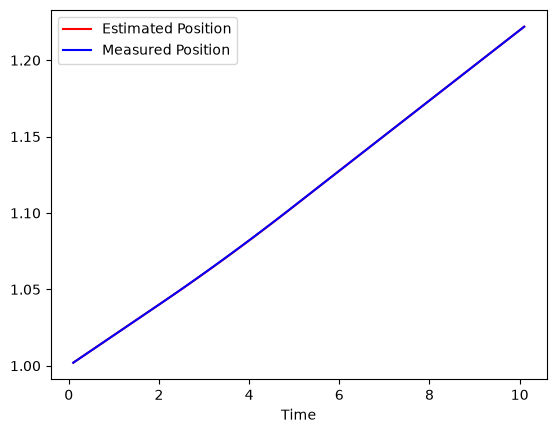

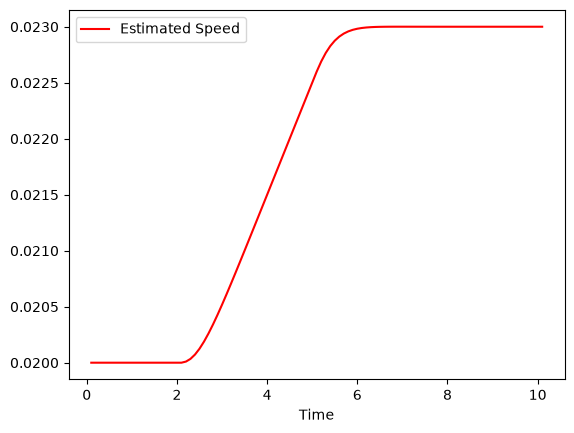

In [58]:
#
#
import arslabrobotics as ar
import numpy as np
import random

# system model
delta_t = 0.1

# p(k+1) = p(k) + delta_t*v(k)
# v(k+1) = v(k)
A = np.array( [ [1 , delta_t],
                [0, 1] ])

# initial state
# p(k) = 1 m
# v(k) = 0.02 m/s
x = np.array( [ [1], [0.02] ])

# create an array of measures
measures = []
p = x[0,0]
v = x[1,0]
# first two seconds, speed constant
for _ in range(20):
    p = p + v * delta_t
    measures.append(p)
# then 3 seconds of small acceleration
for _ in range(30):
    v = v + 0.001 * delta_t
    p = p + v * delta_t
    measures.append(p)
# then 5 seconds of constant speed
for _ in range(50):
    p = p + v * delta_t
    measures.append(p)
p = p + v * delta_t
measures.append(p)

pos = ar.data.DataPlotter()
pos.set_x("Time")
pos.add_y("epos", "Estimated Position")
pos.add_y("mpos", "Measured Position")

vel = ar.data.DataPlotter()
vel.set_x("Time")
vel.add_y("vel", "Estimated Speed")

tm = ar.utils.Time(use_fake_time = True)
while tm.get() < 10:
    tm.sleep(delta_t)
    tm.elapsed()
    t = tm.get()
    
    # estimate next state using system model
    x = A @ x
    
    pos.append_x(tm.get())
    pos.append_y("epos", x[0,0])

    vel.append_x(tm.get())
    vel.append_y("vel", x[1,0])

    # get measure
    p_meas = measures.pop(0) #+ random.gauss(sigma = 1e-3) # add measurement noise
    pos.append_y("mpos", p_meas)
    
    # compute error
    err = p_meas -  x[0,0]
    
    k_pos = 0.5
    k_speed = 0.1

    # correct state
    x[0,0] = x[0,0] + k_pos * err
    x[1,0] = x[1,0] + (k_speed / delta_t) * err
    

pos.plot()
vel.plot()

    